<a href="https://colab.research.google.com/github/mrayhanz/244107020027-Machine-Learning/blob/main/Minggu%204/MRayhanZamzami_JS04_T1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IDENTITAS DIRI

Nama : Muhammad Rayhan Zamzami

NIM : 244107020027

Kelas : TI-3G

Absen : 19

# TUGAS PRAKTIKUM - TUGAS 1

## Tugas 1

In [51]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [52]:
df = pd.read_csv('/content/drive/MyDrive/ml-semester5/dataset/Mall_Customers.csv')
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [59]:
# Menentukan fitur yang digunakan untuk clustering
fitur = ['Annual Income (k$)', 'Spending Score (1-100)']

data = df.loc[:, fitur]

# Standardisasi data
scaler = StandardScaler()
X = scaler.fit_transform(data)

In [60]:
# Mencari jumlah cluster menggunakan metode Elbow
nilai_k = range(2, 11)
sse = []

for jumlah in nilai_k:
    model = KMeans(
        n_clusters=jumlah,
        random_state=0,
        n_init=10
    )

    model.fit(X)
    sse.append(model.inertia_)

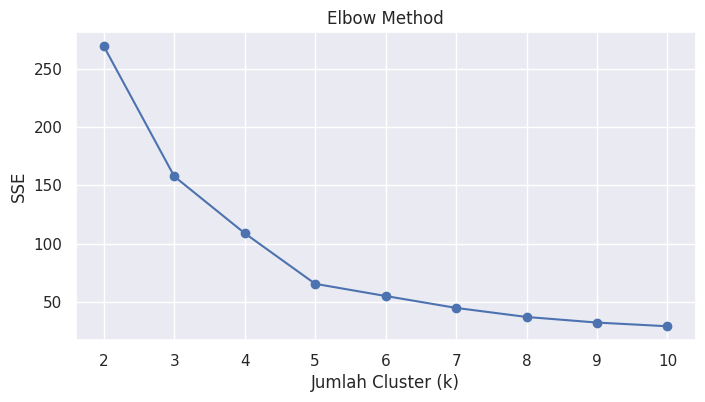

In [61]:
# Visualisasi Elbow Method
plt.figure(figsize=(8, 4))
plt.plot(nilai_k, sse, marker='o')

plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('SSE')
plt.title('Elbow Method')

plt.show()

In [62]:
for jumlah, nilai in zip(nilai_k, sse):
    print(f'Jumlah cluster = {jumlah}, SSE = {nilai:.4f}')

Jumlah cluster = 2, SSE = 269.2993
Jumlah cluster = 3, SSE = 157.7040
Jumlah cluster = 4, SSE = 108.9213
Jumlah cluster = 5, SSE = 65.5684
Jumlah cluster = 6, SSE = 55.1142
Jumlah cluster = 7, SSE = 44.9112
Jumlah cluster = 8, SSE = 37.1481
Jumlah cluster = 9, SSE = 32.3458
Jumlah cluster = 10, SSE = 29.1790


In [63]:
# Membuat model akhir dengan k = 5
k_terbaik = 5

model_kmeans = KMeans(
    n_clusters=k_terbaik,
    random_state=0,
    n_init=10
)

cluster = model_kmeans.fit_predict(X)

df['Cluster'] = cluster

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,3
1,2,Male,21,15,81,4
2,3,Female,20,16,6,3
3,4,Female,23,16,77,4
4,5,Female,31,17,40,3


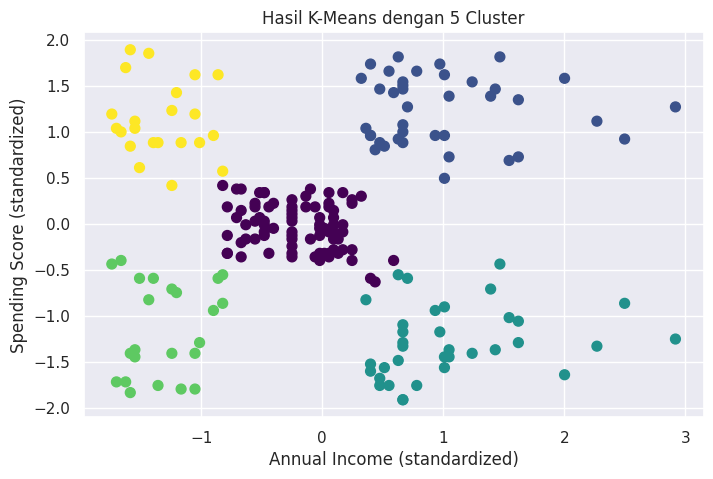

In [64]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=cluster,
    s=50,
    cmap='viridis'
)

plt.xlabel('Annual Income (standardized)')
plt.ylabel('Spending Score (standardized)')
plt.title(f'Hasil K-Means dengan {k_terbaik} Cluster')

plt.show()